In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from clima_ecuador import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
R = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
def figura(nombre, ancho=950):
    display(Image(filename=str(config.FIGURAS / nombre), width=ancho))
def reporte(nombre):
    return pd.read_csv(config.REPORTES / nombre)

# 02 · Clima normal y estacionalidad por región

**Pregunta:** antes de buscar cambios, ¿cómo es el clima "normal" (1981–2010) de cada región?

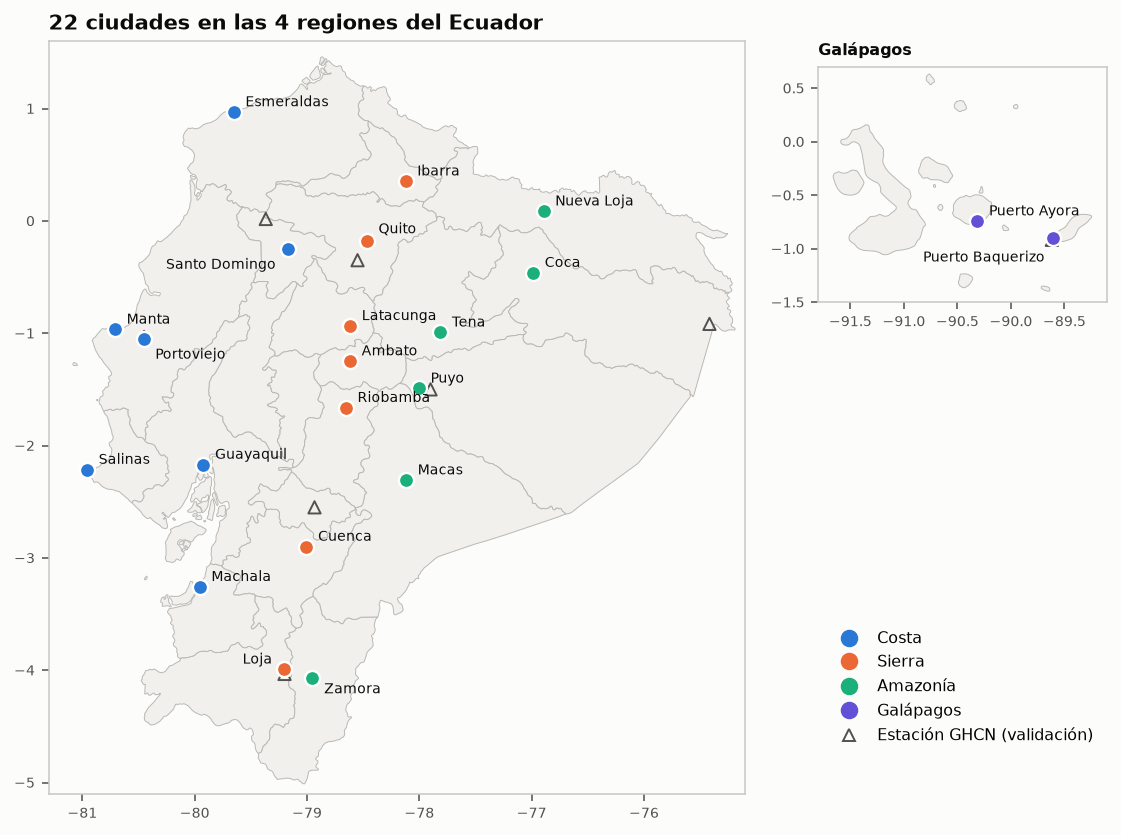

In [2]:
figura("01_mapa_ciudades.png", 800)

In [3]:
clim = pd.read_csv(config.PROCESADOS / "climatologia_regiones.csv")
anual = clim.groupby("region").agg(lluvia_mm=("precip", "sum"), tmax=("tmax", "mean"), tmin=("tmin", "mean"),
                                   humedad=("humedad", "mean"), radiacion=("radiacion", "mean"))
anual.round(1)

,lluvia_mm,tmax,tmin,humedad,radiacion
region,,,,,
Amazonía,"2,961.300",27.400,20.000,86.700,16.500
Costa,"1,605.800",27.500,22.100,83.000,15.900
Galápagos,441.800,25.000,22.200,80.900,21.500
Sierra,"2,009.600",19.100,10.800,82.500,17.600


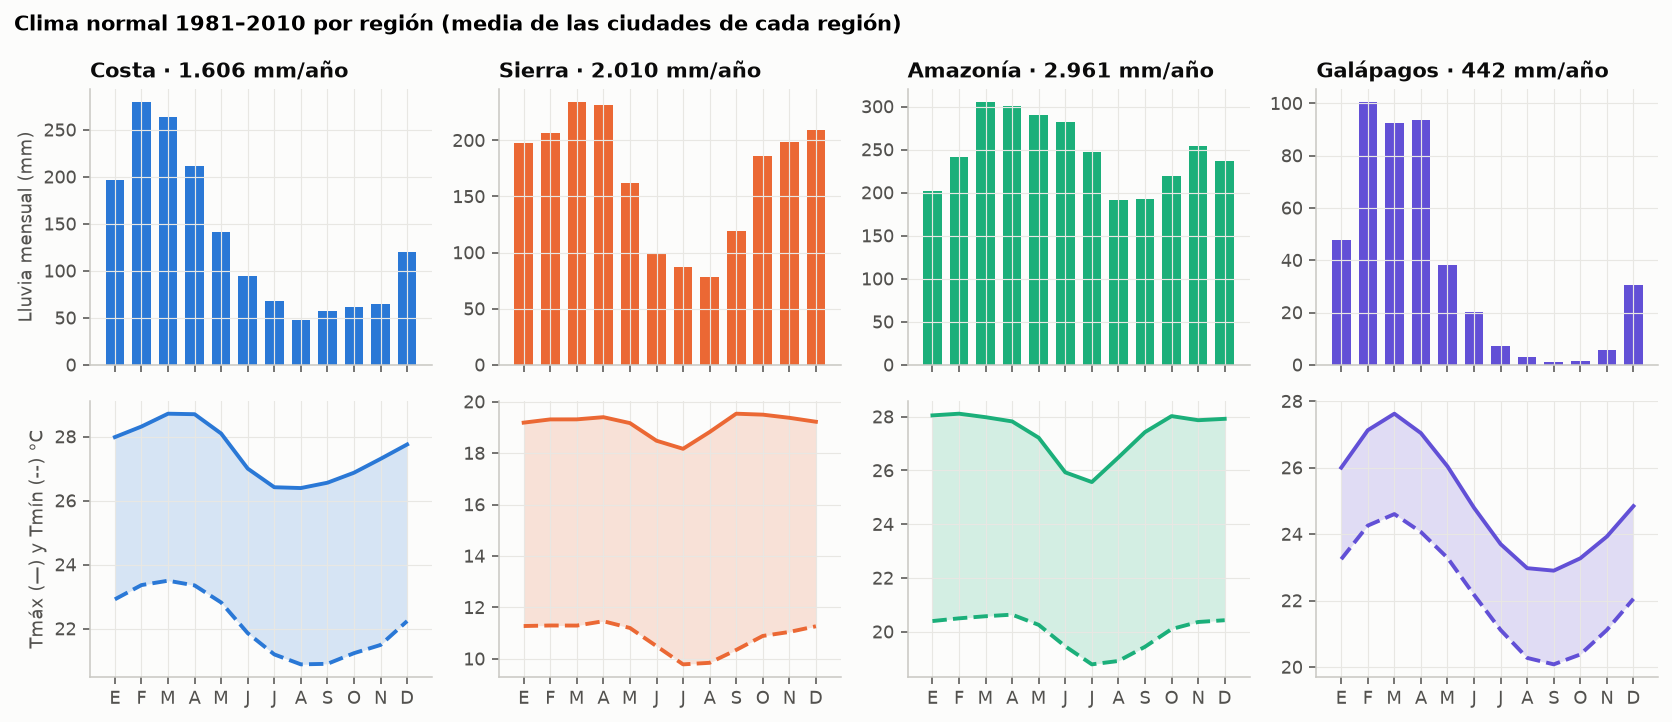

In [4]:
figura("03_climatologia_regiones.png")

In [5]:
reporte("estacionalidad_lluvia.csv").round(2)

,region,lluvia_anual_mm,mes_mas_lluvioso,mes_mas_seco,pct_4_meses,indice_estacionalidad
0,Amazonía,"2,961.330",3,8,39.730,0.130
1,Costa,"1,605.760",2,8,59.250,0.530
2,Galápagos,441.820,2,9,75.630,0.850
3,Sierra,"2,009.580",3,8,43.890,0.290


* **Costa**: una sola estación lluviosa (feb–abr) que concentra el 59 % de la lluvia; julio–noviembre casi seco.
* **Sierra**: régimen **bimodal** (máximos en mar–abr y oct–dic), típico de los Andes ecuatoriales por el doble
  paso de la zona de convergencia intertropical. La temperatura casi no cambia en el año (±1 °C).
* **Amazonía**: llueve todo el año (índice de estacionalidad 0,13); la temperatura baja un poco en junio–julio.
* **Galápagos**: la más estacional (76 % de la lluvia en 4 meses) y la más seca: el mar frío de la corriente de
  Humboldt inhibe la lluvia de junio a noviembre.

⚠️ Los totales de lluvia de la Sierra (2 010 mm/año) están **inflados**: Quito recibe ~1 100–1 300 mm en estaciones.
Ver la validación en el notebook 06.

## Ciclo diario (datos horarios)

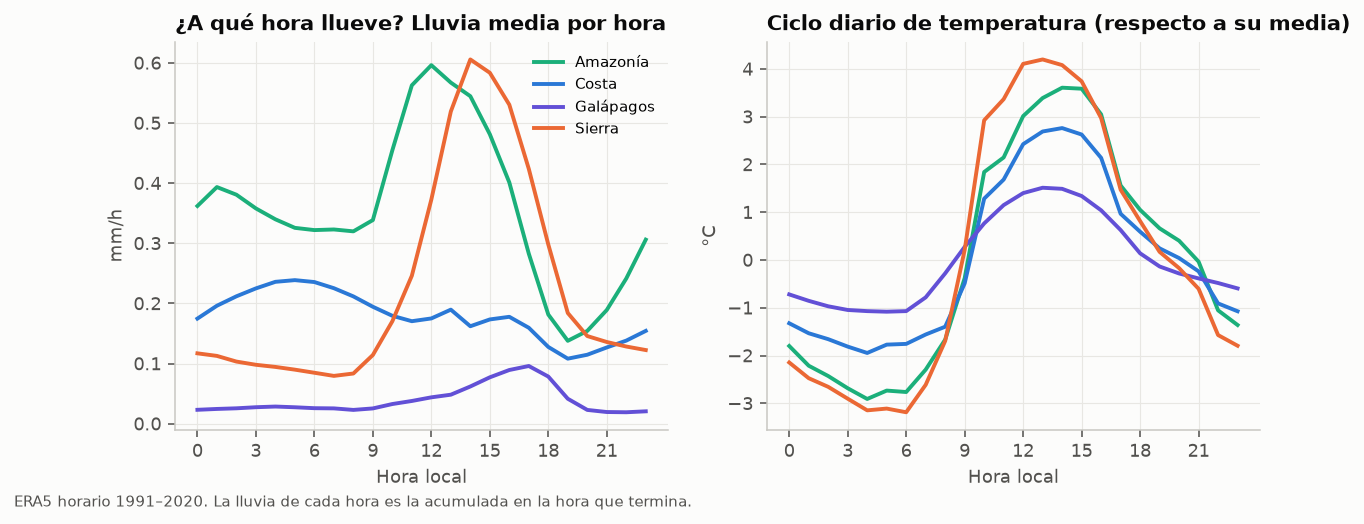

,region,hora,precip
12,Amazonía,12,0.596
29,Costa,5,0.239
65,Galápagos,17,0.096
86,Sierra,14,0.606


In [6]:
figura("04_ciclo_diurno.png")
ciclo = pd.read_csv(config.PROCESADOS / "ciclo_diurno.csv")
ciclo.loc[ciclo.groupby("region")["precip"].idxmax(), ["region", "hora", "precip"]]

La lluvia de la Sierra y la Amazonía es **convectiva de la tarde** (pico a las 12–14 h: el sol calienta el
suelo, el aire sube y forma nubes de tormenta). La Costa tiene el máximo de madrugada y Galápagos casi no tiene ciclo.
La amplitud térmica diaria es mayor en la Sierra (≈ 7 °C) que en Galápagos (≈ 2,5 °C), donde el mar la amortigua.